In [1]:
from typing import List, TypedDict
from langgraph.graph import StateGraph, START , END



In [ ]:
class AgentState(TypedDict):
    num1: int
    num2: int
    operation1: str
    num3: int
    num4: int
    operation2: str
    finalNum1: int
    finalNum2: int


def add_node1(state:AgentState) -> AgentState:
    """
    Adds a new node to the graph and returns the updated state.
    """
    state['finalNum1'] = state['num1'] + state['num2']
    return state

def add_node2(state:AgentState) -> AgentState:
    """
    Adds a new node to the graph and returns the updated state.
    """
    state['finalNum2'] = state['num3'] + state['num4']
    return state

def sub_node1(state:AgentState) -> AgentState:
    """
    Subtracts num2 from num1 and returns the updated state.
    """
    state['finalNum1'] = state['num1'] - state['num2']
    return state

def sub_node2(state:AgentState) -> AgentState:
    """
    Subtracts num4 from num3 and returns the updated state.
    """
    state['finalNum2'] = state['num3'] - state['num4']
    return state



In [5]:
def conditional_node(state:AgentState) -> AgentState:
    """
    Performs a conditional operation based on the values of finalNum1 and finalNum2.
    If finalNum1 is greater than finalNum2, it adds them; otherwise, it subtracts them.
    """
    if state["operation1"] == "+":
        return "add_operation"
    elif state["operation1"] == "-":
        return "sub_operation"
    else:
        raise ValueError("Invalid operation1. Must be '+' or '-'.")
    
def conditional_node2(state:AgentState) -> AgentState:
    """
    Performs a conditional operation based on the values of finalNum1 and finalNum2.
    If finalNum1 is greater than finalNum2, it adds them; otherwise, it subtracts them.
    """
    if state["operation2"] == "+":
        return "add_operation2"
    elif state["operation2"] == "-":
        return "sub_operation2"
    else:
        raise ValueError("Invalid operation2. Must be '+' or '-'.")

In [8]:
graph = StateGraph(AgentState)

graph.add_node("add_operation", add_node1)
graph.add_node("sub_operation", sub_node1)
graph.add_node("add_operation2", add_node2)
graph.add_node("sub_operation2", sub_node2)

graph.add_node("router", lambda state:state)
graph.add_node("router2", lambda state:state)

graph.add_edge(START, "router")

graph.add_conditional_edges("router", conditional_node, {
    "add_operation": "add_operation",
    "sub_operation": "sub_operation"
})

graph.add_edge("add_operation", "router2")
graph.add_edge("sub_operation", "router2")

graph.add_conditional_edges("router2", conditional_node2, {
    "add_operation2": "add_operation2",
    "sub_operation2": "sub_operation2"
})

graph.add_edge("add_operation2", END)
graph.add_edge("sub_operation2", END)

app = graph.compile()

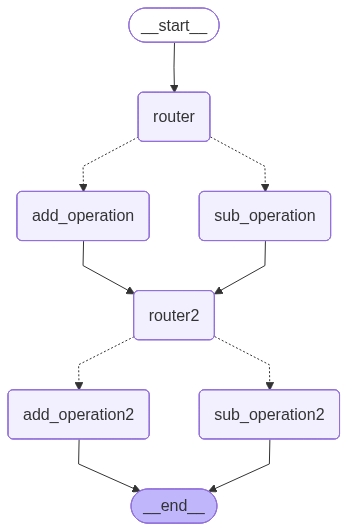

In [9]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [10]:
result = app.invoke({"finalNum1": 0, "finalNum2": 0, "num1": 10, "num2": 5, "operation1": "+", "num3": 20, "num4": 8, "operation2": "-"})
print(result)

{'num1': 10, 'num2': 5, 'operation1': '+', 'num3': 20, 'num4': 8, 'operation2': '-', 'finalNum1': 15, 'finalNum2': 12}
